In [14]:
import pandas as pd
import torch
import torch.nn as nn

### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [13]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

df = df[df["species"].isin(["setosa", "versicolor"])].copy()

df["species"] = df["species"].map({"setosa": 0, "versicolor": 1})

X_all = torch.tensor(df.drop(columns=["species"]).values, dtype=torch.float32)
y_all = torch.tensor(df["species"].values, dtype=torch.float32).unsqueeze(1)


torch.manual_seed(42)
num_data = len(X_all)
num_train = int(num_data * 0.8)

indices = torch.randperm(num_data)

train_indices = indices[:num_train]
test_indices = indices[num_train:]

X_train_tensor = X_all[train_indices]
y_train_tensor = y_all[train_indices]

X_test_tensor = X_all[test_indices]
y_test_tensor = y_all[test_indices]

train_mean = X_train_tensor.mean(dim=0)
train_std = X_train_tensor.std(dim=0)

X_train_tensor = (X_train_tensor - train_mean) / train_std
X_test_tensor = (X_test_tensor - train_mean) / train_std

print(f"X_train_tensor 형태: {X_train_tensor.shape}")
print(f"y_train_tensor 형태: {y_train_tensor.shape}")

X_train_tensor 형태: torch.Size([80, 4])
y_train_tensor 형태: torch.Size([80, 1])


#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [ ]:
class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.model = nn.Sequential(
            nn.Linear(4, 100),
            nn.ReLU(),
            nn.Linear(100, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.model(x)

model = IrisClassifier()

dummy_x = torch.randn(3, 4) 

probabilities = model(dummy_x)

predictions = (probabilities >= 0.5).float()

print("--- 예측 테스트 ---")
print(f"확률(Probabilities):\n{probabilities.detach()}")
print(f"최종 분류 클래스(Predictions):\n{predictions.detach()}")

--- 예측 테스트 ---
확률(Probabilities):
tensor([[0.5290],
        [0.4310],
        [0.4599]])
최종 분류 클래스(Predictions):
tensor([[1.],
        [0.],
        [0.]])


#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [33]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

LR = 0.1
EPOCHS = 100
BATCH_SIZE = 16

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=LR)

model.train()

print("--- 학습 시작 ---")
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        avg_loss = epoch_loss / len(train_loader)
        print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {avg_loss:.4f}')

print("--- 학습 완료! ---")

--- 학습 시작 ---
Epoch [10/100], Loss: 0.0001
Epoch [20/100], Loss: 0.0001
Epoch [30/100], Loss: 0.0001
Epoch [40/100], Loss: 0.0001
Epoch [50/100], Loss: 0.0001
Epoch [60/100], Loss: 0.0001
Epoch [70/100], Loss: 0.0001
Epoch [80/100], Loss: 0.0001
Epoch [90/100], Loss: 0.0001
Epoch [100/100], Loss: 0.0001
--- 학습 완료! ---


#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [34]:
model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    predictions = (test_outputs >= 0.5).float()
    
    correct_count = (predictions == y_test_tensor).sum().item()
    
    total_count = y_test_tensor.size(0)
    
    accuracy = (correct_count / total_count) * 100

print("=== Step 4. 모델 테스트 결과 ===")
print(f"총 테스트 데이터 : {total_count}개")
print(f"정답을 맞힌 개수 : {correct_count}개")
print(f"Accuracy(정확도) : {accuracy:.2f}%")

=== Step 4. 모델 테스트 결과 ===
총 테스트 데이터 : 20개
정답을 맞힌 개수 : 20개
Accuracy(정확도) : 100.00%


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

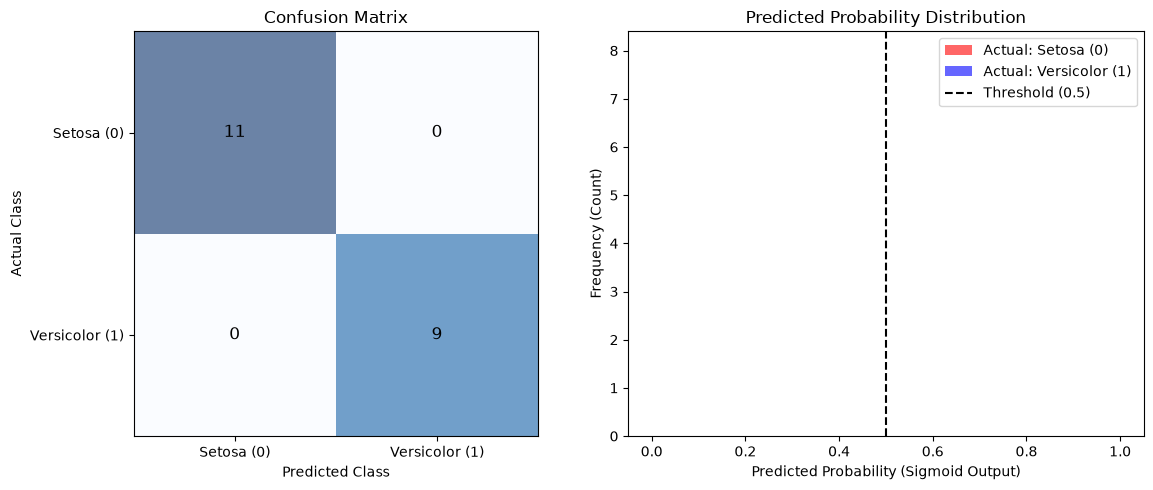

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

y_true = y_test_tensor.numpy()
y_pred = predictions.numpy()
probs = test_outputs.numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_true, y_pred)

axes[0].imshow(cm, interpolation='nearest', cmap='Blues', alpha=0.6)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(x=j, y=i, s=cm[i, j], ha='center', va='center', color='black', fontsize=12)

axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Setosa (0)', 'Versicolor (1)'])
axes[0].set_yticklabels(['Setosa (0)', 'Versicolor (1)'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Actual Class')

probs_class0 = probs[y_true == 0]
probs_class1 = probs[y_true == 1]

axes[1].hist(probs_class0, bins=10, alpha=0.6, color='red', label='Actual: Setosa (0)')
axes[1].hist(probs_class1, bins=10, alpha=0.6, color='blue', label='Actual: Versicolor (1)')
axes[1].axvline(0.5, color='black', linestyle='--', label='Threshold (0.5)')

axes[1].set_title('Predicted Probability Distribution')
axes[1].set_xlabel('Predicted Probability (Sigmoid Output)')
axes[1].set_ylabel('Frequency (Count)')
axes[1].legend()

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인

In [36]:
print("=== Step 6. 모델 파라미터(가중치) 개수 확인 ===")

total_params = 0

for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        param_count = parameter.numel()
        print(f"Layer: {name:20} | Size: {list(parameter.size())} | Count: {param_count}")
        total_params += param_count

print("-" * 50)
print(f"총 학습 가능한 파라미터 개수 : {total_params}개")

=== Step 6. 모델 파라미터(가중치) 개수 확인 ===
Layer: model.0.weight       | Size: [100, 4] | Count: 400
Layer: model.0.bias         | Size: [100] | Count: 100
Layer: model.2.weight       | Size: [1, 100] | Count: 100
Layer: model.2.bias         | Size: [1] | Count: 1
--------------------------------------------------
총 학습 가능한 파라미터 개수 : 601개
